# Phase 3: Exploratory Data Analysis (EDA)
## Intelligent E-Commerce Review Router

In this notebook, we perform exploratory data analysis on the customer review dataset to understand:
- Class balances for overall sentiment (`Positive`, `Neutral`, `Negative`)
- Review text character and word length distributions
- Frequency of extracted business aspects (`delivery`, `product_quality`, `payment`, `refund_return`, `packaging`, `customer_support`)
- Routing department allocations and support priority levels (`LOW`, `MEDIUM`, `HIGH`, `URGENT`)

In [1]:
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Setting plot styles
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 5)
print("EDA libraries loaded successfully!")

EDA libraries loaded successfully!


In [2]:
# Load processed dataset
data_path = "../data/processed/ecommerce_reviews.csv"
if not os.path.exists(data_path):
    data_path = "data/processed/ecommerce_reviews.csv"

df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (1500, 8)


,review_id,product,review,sentiment,aspects,issues_json,department,priority
0,REV-00001,laptop,"The laptop is crystal clear display, but poor ...",Neutral,"product_quality,customer_support,packaging","[{""aspect"": ""product_quality"", ""opinion"": ""cry...",Product Support,MEDIUM
1,REV-00002,smartphone,support team is polite and quick for my recent...,Positive,customer_support,"[{""aspect"": ""customer_support"", ""opinion"": ""su...",Customer Support,LOW
2,REV-00003,desk lamp,I am unhappy with the desk lamp. stopped worki...,Negative,"product_quality,refund_return","[{""aspect"": ""product_quality"", ""opinion"": ""sto...",Product Support,URGENT
3,REV-00004,laptop,I am unhappy with the laptop. courier was rude...,Negative,"packaging,payment,delivery","[{""aspect"": ""packaging"", ""opinion"": ""standard ...",Returns / Replacement,MEDIUM
4,REV-00005,laptop,I am unhappy with the laptop. charged twice fo...,Negative,"payment,delivery","[{""aspect"": ""payment"", ""opinion"": ""charged twi...",Payments,HIGH


In [3]:
print("--- Data Information ---")
print(df.info())
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Duplicate Count ---")
print(df.duplicated(subset=['review']).sum())

--- Data Information ---
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    1500 non-null   str  
 1   product      1500 non-null   str  
 2   review       1500 non-null   str  
 3   sentiment    1500 non-null   str  
 4   aspects      1500 non-null   str  
 5   issues_json  1500 non-null   str  
 6   department   1500 non-null   str  
 7   priority     1500 non-null   str  
dtypes: str(8)
memory usage: 565.7 KB
None

--- Missing Values ---
review_id      0
product        0
review         0
sentiment      0
aspects        0
issues_json    0
department     0
priority       0
dtype: int64

--- Duplicate Count ---
357


C:\Users\Navnath\AppData\Local\Temp\ipykernel_18396\2663787020.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='sentiment', palette='Set2')


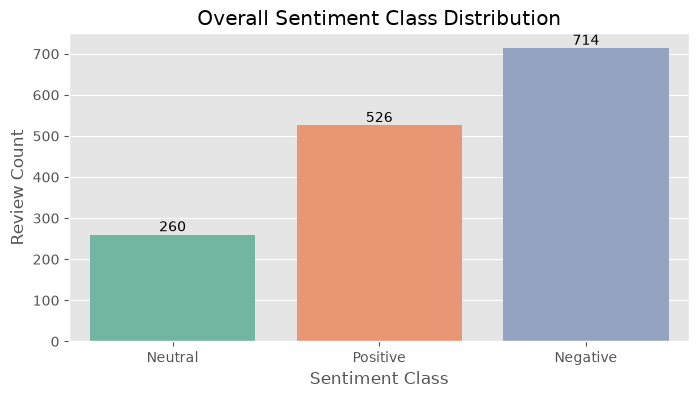

sentiment
Negative    47.60
Positive    35.07
Neutral     17.33
Name: proportion, dtype: float64


In [4]:
# Sentiment distribution
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x='sentiment', palette='Set2')
plt.title('Overall Sentiment Class Distribution')
plt.xlabel('Sentiment Class')
plt.ylabel('Review Count')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.show()

print(df['sentiment'].value_counts(normalize=True).round(4) * 100)

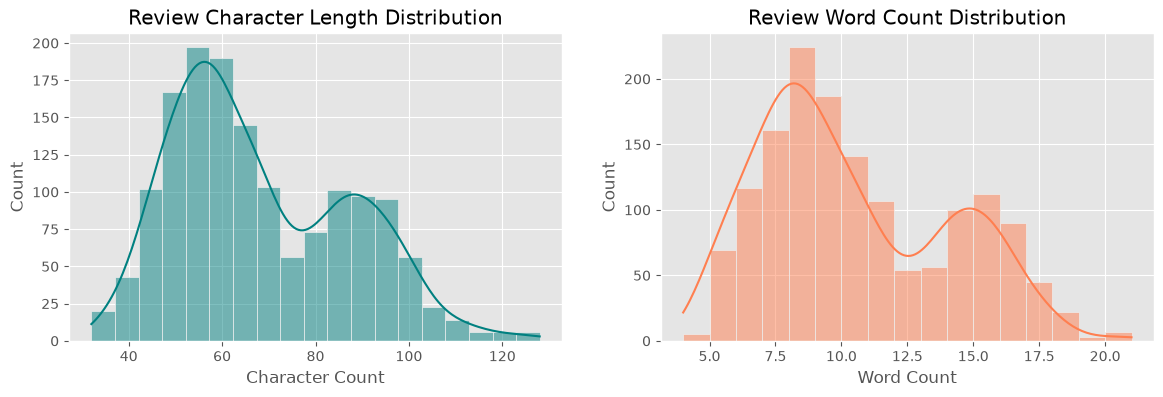

       char_length   word_count
count  1500.000000  1500.000000
mean     68.206000    10.342667
std      18.894167     3.582616
min      32.000000     4.000000
25%      54.000000     8.000000
50%      64.000000     9.000000
75%      84.000000    14.000000
max     128.000000    21.000000


In [5]:
# Review length analysis
df['char_length'] = df['review'].astype(str).str.len()
df['word_count'] = df['review'].astype(str).apply(lambda x: len(x.split()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['char_length'], kde=True, ax=axes[0], color='teal')
axes[0].set_title('Review Character Length Distribution')
axes[0].set_xlabel('Character Count')

sns.histplot(df['word_count'], kde=True, ax=axes[1], color='coral')
axes[1].set_title('Review Word Count Distribution')
axes[1].set_xlabel('Word Count')
plt.show()

print(df[['char_length', 'word_count']].describe())

C:\Users\Navnath\AppData\Local\Temp\ipykernel_18396\850590584.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=aspect_counts.values, y=aspect_counts.index, palette='Blues_r')


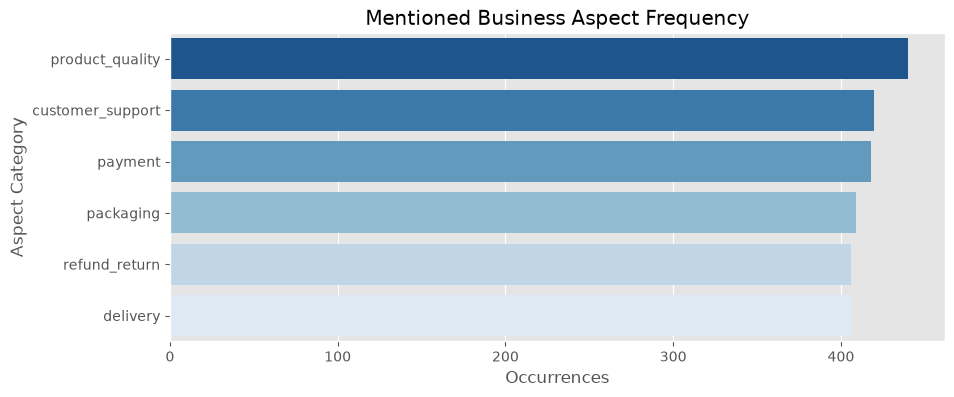

product_quality     440
customer_support    420
payment             418
packaging           409
refund_return       406
delivery            406
Name: count, dtype: int64


In [6]:
# Aspect frequency breakdown
all_aspects = []
for aspect_str in df['aspects'].dropna():
    all_aspects.extend([a.strip() for a in aspect_str.split(',') if a.strip()])

aspect_counts = pd.Series(all_aspects).value_counts()
plt.figure(figsize=(10, 4))
sns.barplot(x=aspect_counts.values, y=aspect_counts.index, palette='Blues_r')
plt.title('Mentioned Business Aspect Frequency')
plt.xlabel('Occurrences')
plt.ylabel('Aspect Category')
plt.show()
print(aspect_counts)

C:\Users\Navnath\AppData\Local\Temp\ipykernel_18396\682978366.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='department', ax=axes[0], palette='crest', order=df['department'].value_counts().index)
C:\Users\Navnath\AppData\Local\Temp\ipykernel_18396\682978366.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')
C:\Users\Navnath\AppData\Local\Temp\ipykernel_18396\682978366.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='priority', ax=axes[1], palette='flare', order

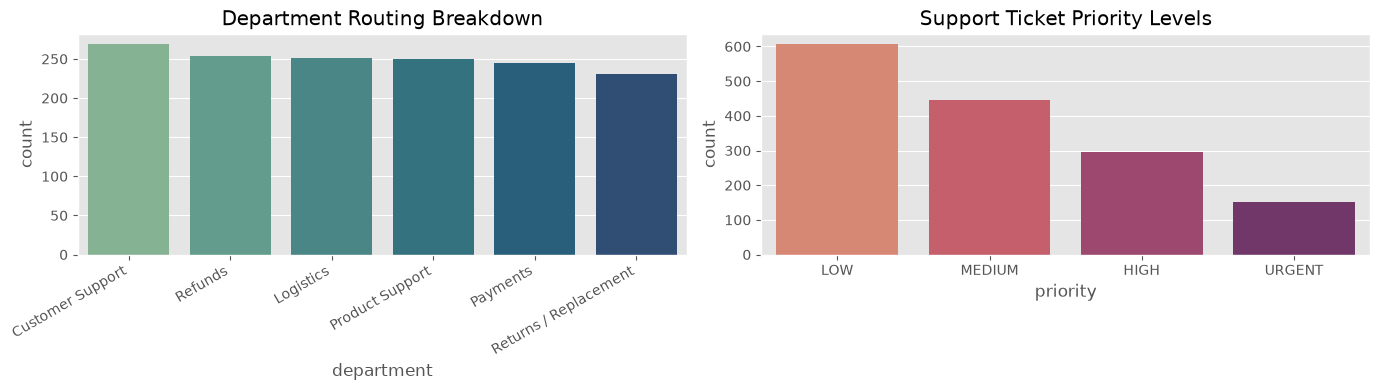

--- Priority by Sentiment Cross-Tabulation ---
priority   HIGH  LOW  MEDIUM  URGENT
sentiment                           
Negative    239    0     324     151
Neutral      43  123      94       0
Positive     13  484      29       0


In [7]:
# Department & Priority analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df, x='department', ax=axes[0], palette='crest', order=df['department'].value_counts().index)
axes[0].set_title('Department Routing Breakdown')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha='right')

sns.countplot(data=df, x='priority', ax=axes[1], palette='flare', order=['LOW', 'MEDIUM', 'HIGH', 'URGENT'])
axes[1].set_title('Support Ticket Priority Levels')
plt.tight_layout()
plt.show()

print("--- Priority by Sentiment Cross-Tabulation ---")
print(pd.crosstab(df['sentiment'], df['priority']))